
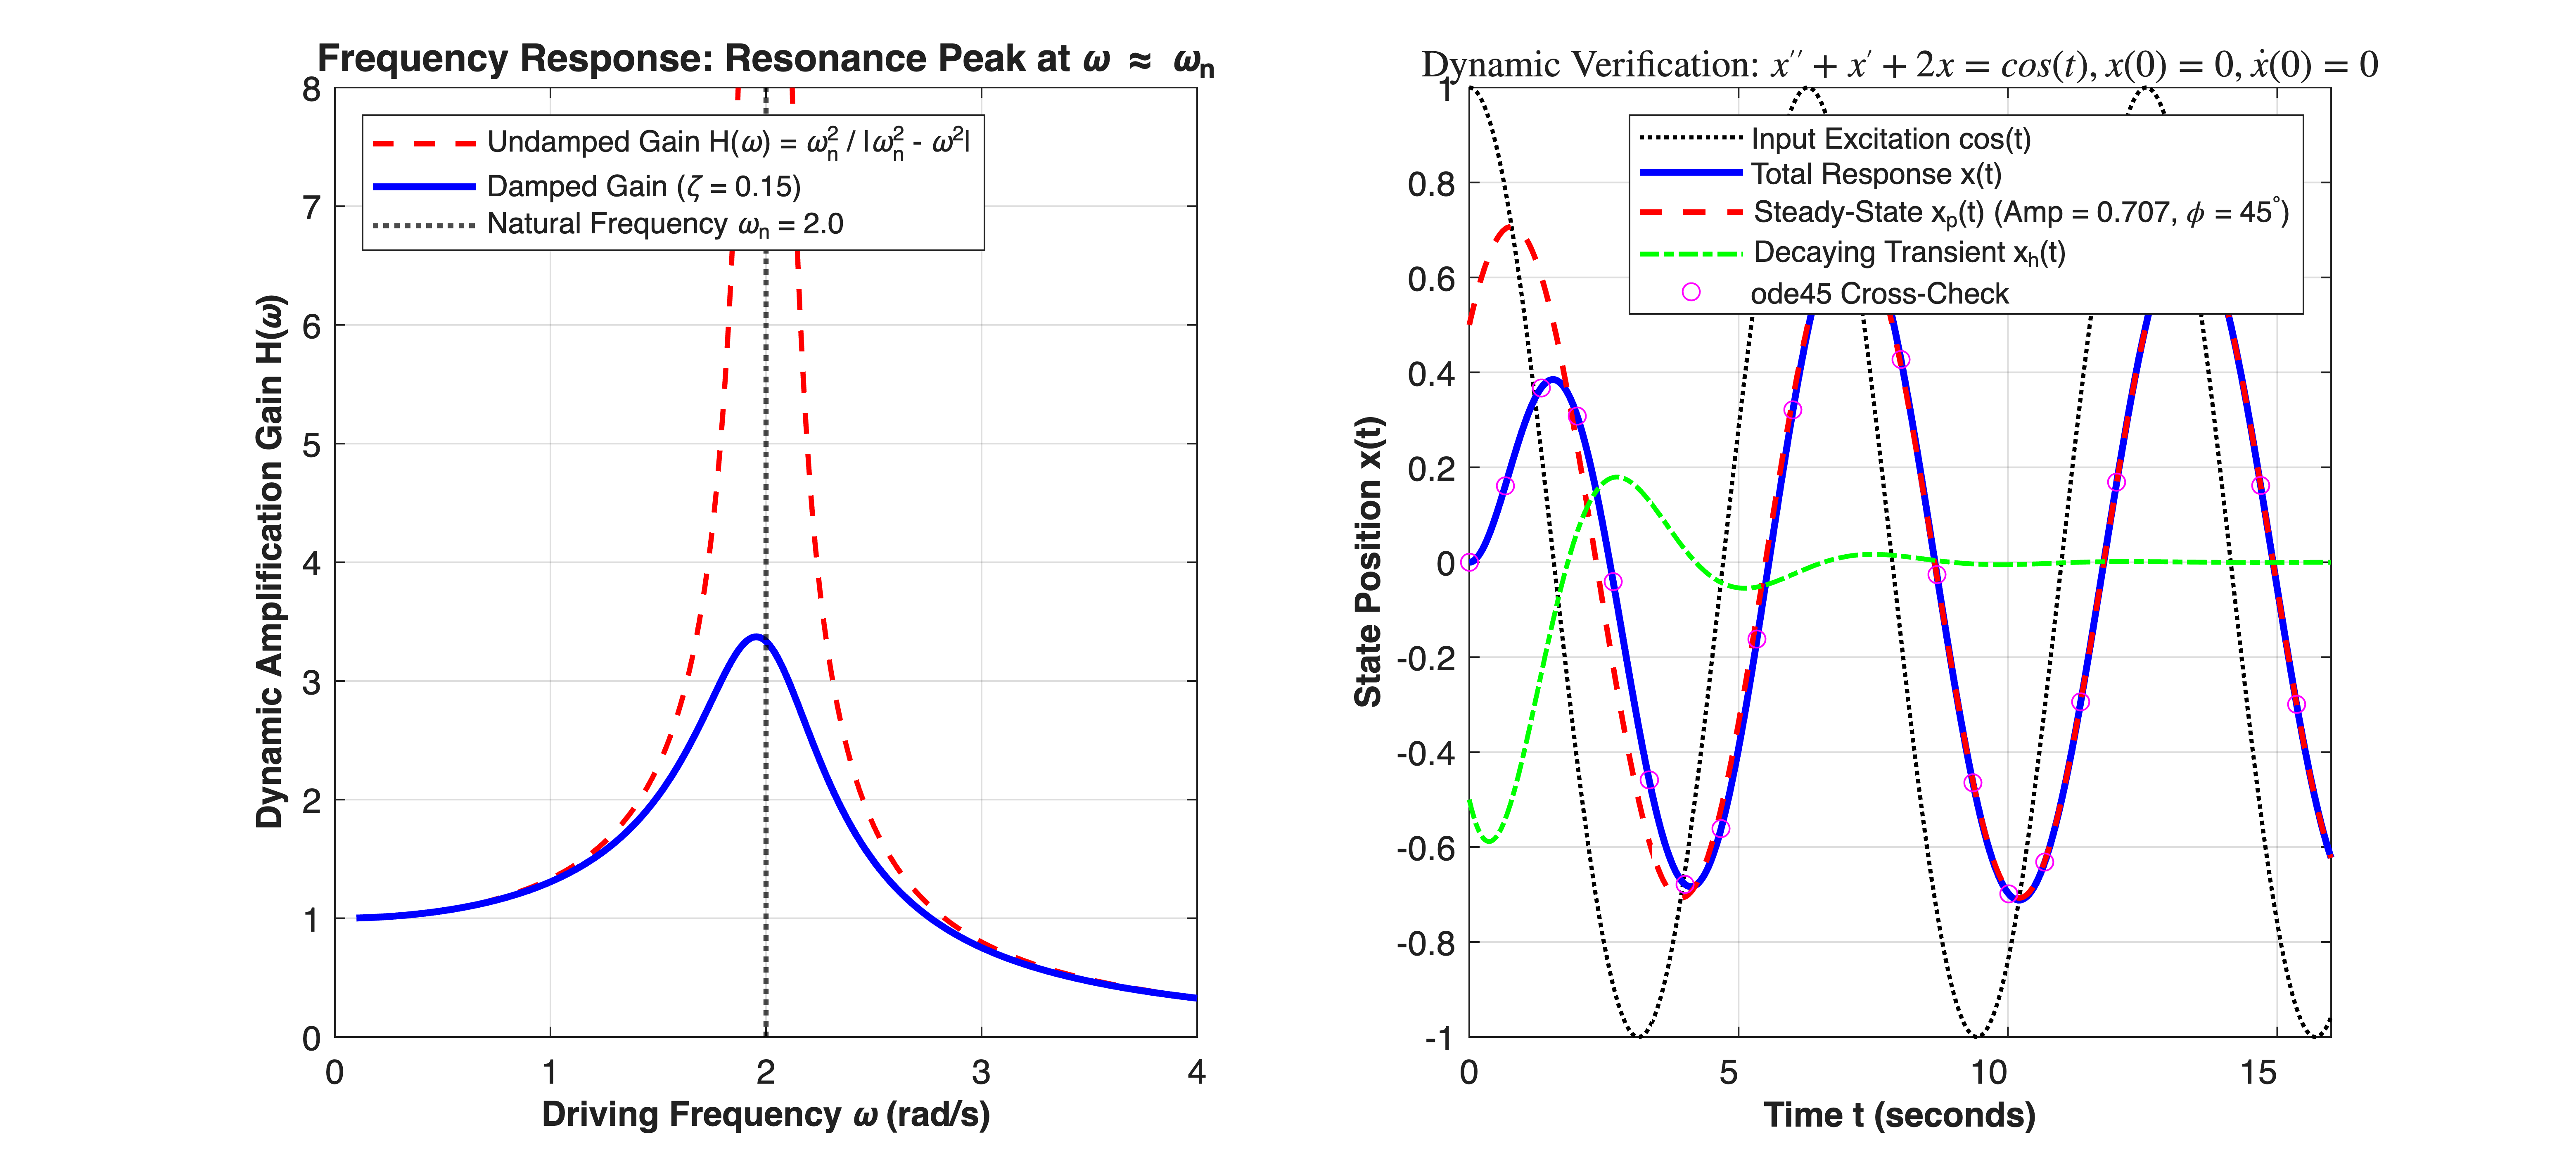

In [1]:
%% MIT 18.03 Lecture 13: Forced Linear Systems, Resonance & Complex Replacement
% Description: Simulates forced 2nd-order dynamics:
%              1) Frequency-domain gain and phase curves showing undamped resonance & phase reversal.
%              2) Time-domain dynamic response for x'' + x' + 2x = cos(t) with decomposition.
%
% % Required Toolboxes:
% %   - Base MATLAB (Core functionality: complex phasors, ode45 integration).
% % Optional Toolboxes:
% %   - Control System Toolbox (Equivalent to bode, lsim, and freqresp).
%
% % MBD Concept Mapping: Demonstrates frequency response G(jw) = 1/p(jw).
% %                      Validates dynamic amplification near resonance (w -> w_n),
% %                      phase lag caused by damping b, and Superposition II (Total = x_p + x_h).


clear; clc; close all;


%% =========================================================================
%% Part 1: Frequency Response & Resonance Curves (Lecture Section [2])
%% =========================================================================
w_n = 2.0; % System natural frequency: 2 rad/s
w_vec = linspace(0.1, 4.0, 600);


% Undamped Gain: H(w) = w_n^2 / |w_n^2 - w^2|
Gain_undamped = (w_n^2) ./ abs(w_n^2 - w_vec.^2);


% Damped Gain: H_damped(w) = w_n^2 / | -w^2 + 2*zeta*w_n*1i*w + w_n^2 |
zeta = 0.15; % Light damping ratio
p_jw_damped = -w_vec.^2 + 1i * (2 * zeta * w_n * w_vec) + w_n^2;
Gain_damped = (w_n^2) ./ abs(p_jw_damped);
Phase_damped = -angle(p_jw_damped) * (180 / pi); % Phase lag in degrees


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Dynamic Amplification Gain vs Driving Frequency
subplot(1, 2, 1);
hold on; grid on; box on;
plot(w_vec, Gain_undamped, 'r--', 'LineWidth', 1.5, ...
     'DisplayName', 'Undamped Gain H(\omega) = \omega_n^2 / |\omega_n^2 - \omega^2|');
plot(w_vec, Gain_damped, 'b-', 'LineWidth', 2.0, ...
     'DisplayName', sprintf('Damped Gain (\\zeta = %.2f)', zeta));
xline(w_n, 'k:', 'LineWidth', 1.5, 'DisplayName', 'Natural Frequency \omega_n = 2.0');


ylim([0, 8]);
xlabel('Driving Frequency \omega (rad/s)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Dynamic Amplification Gain H(\omega)', 'FontSize', 10, 'FontWeight', 'bold');
title('Frequency Response: Resonance Peak at \omega \approx \omega_n', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);


%% =========================================================================
%% Part 2: Lecture Benchmark Simulation: x'' + x' + 2x = cos(t) (Section [4])
%% =========================================================================
% Equation parameters: m = 1, b = 1, k = 2, F0 = 1, w_drive = 1
% Input phasor: F0 = 1. Characteristic poly: p(s) = s^2 + s + 2
% Evaluation at driving frequency s = 1i: p(1i) = (1i)^2 + 1i + 2 = 1 + 1i
p_eval = 1 + 1i;
Z_p = 1 / p_eval;             % Z_p = (1 - 1i)/2
A_ss = abs(Z_p);              % sqrt(2)/2 ~ 0.7071
phi_ss = -angle(Z_p);         % pi/4 rad (45 deg lag)


t_span = [0, 16];
t_eval = linspace(t_span(1), t_span(2), 600);


% Analytical Particular Solution: x_p(t) = (sqrt(2)/2)*cos(t - pi/4)
x_p_eval = A_ss * cos(1.0 * t_eval - phi_ss);


% Analytical Homogeneous Transient: roots of s^2 + s + 2 = 0 -> -0.5 +/- 1i*(sqrt(7)/2)
alpha = -0.5;
w_d = sqrt(7) / 2;
% Initial conditions: x(0) = 0, x'(0) = 0
% x(0) = x_p(0) + c1 = 0 -> c1 = -x_p(0) = -0.5
% x'(0) = x_p'(0) + alpha*c1 + w_d*c2 = 0 -> x_p'(0) = 0.5 -> c2 = -(0.5 + alpha*c1)/w_d
c1 = -0.5;
c2 = -(0.5 + alpha * c1) / w_d; % c2 = -0.75 / (sqrt(7)/2) = -1.5 / sqrt(7)
x_h_eval = exp(alpha * t_eval) .* (c1 * cos(w_d * t_eval) + c2 * sin(w_d * t_eval));


% Total Analytical Response (Superposition II)
x_total_analytical = x_p_eval + x_h_eval;


% Numerical ODE45 Integration Cross-Check
ode_system = @(t, X) [X(2); -X(2) - 2*X(1) + cos(t)];
opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);
[~, X_num] = ode45(ode_system, t_eval, [0; 0], opts);


% Subplot 2: Dynamic Response Decomposition
subplot(1, 2, 2);
hold on; grid on; box on;
plot(t_eval, cos(t_eval), 'k:', 'LineWidth', 1.2, 'DisplayName', 'Input Excitation cos(t)');
plot(t_eval, x_total_analytical, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Total Response x(t)');
plot(t_eval, x_p_eval, 'r--', 'LineWidth', 1.6, ...
     'DisplayName', 'Steady-State x_p(t) (Amp = 0.707, \phi = 45^\circ)');
plot(t_eval, x_h_eval, 'g-.', 'LineWidth', 1.4, 'DisplayName', 'Decaying Transient x_h(t)');
plot(t_eval(1:25:end), X_num(1:25:end, 1), 'mo', 'MarkerSize', 5, 'DisplayName', 'ode45 Cross-Check');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Position x(t)', 'FontSize', 10, 'FontWeight', 'bold');
title("Dynamic Verification: $x'' + x' + 2x = cos(t), x(0)=0, \dot{x}(0)=0$", ...
      'FontSize', 11, 'FontWeight', 'bold', 'Interpreter','latex');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 16]);

In [2]:


fprintf('=== MIT 18.03 Lecture 13 Dynamic Diagnostics ===\n');

=== MIT 18.03 Lecture 13 Dynamic Diagnostics ===

In [3]:
fprintf('Driving Frequency (omega)   : 1.00 rad/s\n');

Driving Frequency (omega)   : 1.00 rad/s

In [4]:
fprintf('Characteristic Operator p(i): %+.2f %+.2fi\n', real(p_eval), imag(p_eval));

Characteristic Operator p(i): +1.00 +1.00i

In [5]:
fprintf('Complex Output Phasor Z_p   : %+.4f %+.4fi\n', real(Z_p), imag(Z_p));

Complex Output Phasor Z_p   : +0.5000 -0.5000i

In [6]:
fprintf('Steady Amplitude (A_ss)     : %.4f (Analytical: sqrt(2)/2 = 0.7071)\n', A_ss);

Steady Amplitude (A_ss)     : 0.7071 (Analytical: sqrt(2)/2 = 0.7071)

In [7]:
fprintf('Steady Phase Lag (phi_ss)   : %.4f rad (45.0 degrees)\n', phi_ss);

Steady Phase Lag (phi_ss)   : 0.7854 rad (45.0 degrees)

In [8]:
fprintf('Transient Decay Envelope    : exp(%.2f*t)\n', alpha);

Transient Decay Envelope    : exp(-0.50*t)

In [9]:
fprintf('================================================\n');